# 05 — Decision Tree Classification & Pruning

## Loan Default Risk Classification (Binary Task)


## 1. Imports and Configuration


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'Arial'
plt.rcParams['figure.dpi'] = 150
plt.rcParams['axes.titlesize'] = 12

RANDOM_STATE = 42

DATA_PATH = os.path.join('..', '..', 'data', 'processed', 'loan_featured.xlsx')
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('data', 'processed', 'loan_featured.xlsx')

print(f'Loading data from: {DATA_PATH}')

Loading data from: ..\..\data\processed\loan_featured.xlsx


## 2. Ingestion & Preprocessing Setup


In [2]:
df = pd.read_excel(DATA_PATH, sheet_name='Loan_Featured')

# Binary target
y = (df['Loan_Default'] == 'Yes').astype(int)

# Exclude leakage
drop_cols = ['Applicant_ID', 'Application_Date', 'Risk_Category', 'Loan_Default']
X = df.drop(columns=drop_cols)

# Stratified 80/20 train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

numeric_cols = [
    'Age', 'Years_Employed', 'Annual_Income', 'Loan_Amount', 'Loan_Term_Months',
    'Interest_Rate_Pct', 'Credit_Score', 'Credit_History_Years', 'Existing_Loans',
    'Total_Credit_Limit', 'Credit_Utilization_Pct', 'Late_Payments_2Y',
    'Monthly_Debt_Payment', 'Savings_Balance', 'Checking_Balance',
    'Debt_to_Income', 'Loan_to_Income', 'Loan_to_Value', 'Savings_to_Income',
    'Log_Annual_Income', 'Log_Loan_Amount', 'Log_Savings_Balance'
]

nominal_cols = [
    'Marital_Status', 'Home_Ownership', 'Employment_Type', 'Employer_Sector',
    'Loan_Purpose', 'Region', 'Application_Channel'
]

binary_cols = [
    'Gender', 'Salary_Account_With_Bank', 'Vehicle_Owned', 'Has_Co_Applicant',
    'Previous_Default', 'Mobile_Banking_User', 'Ever_Delinquent', 'Is_Home_Loan'
]

ordinal_cols = ['Education_Level']
education_hierarchy = [['High School', 'Diploma', 'Bachelor', 'Master', 'PhD']]

# Preprocessor: Note decision trees are scale-invariant, but imputing and encoding is necessary
preprocessor = ColumnTransformer(transformers=[
    ('num', SimpleImputer(strategy='median'), numeric_cols),
    ('nom', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))]), nominal_cols),
    ('ord', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('ord', OrdinalEncoder(categories=education_hierarchy))]), ordinal_cols),
    ('bin', Pipeline([('imp', SimpleImputer(strategy='most_frequent')), ('enc', OrdinalEncoder())]), binary_cols)
], remainder='drop')


## 3. Mathematical Impurity & Splitting Calculations


In [3]:
# Computational verification of Gini and Entropy Impurity
p0 = 0.70
p1 = 0.30
gini_parent = 1.0 - (p0**2 + p1**2)
entropy_parent = -(p0 * np.log2(p0) + p1 * np.log2(p1))

print('=== Impurity Calculations ===')
print(f'Gini Impurity: {gini_parent:.4f}')
print(f'Entropy:       {entropy_parent:.5f} bits')


pL1 = 25 / 40
pL0 = 15 / 40
gini_L = 1.0 - (pL1**2 + pL0**2)

pR1 = 5 / 60
pR0 = 55 / 60
gini_R = 1.0 - (pR1**2 + pR0**2)

weighted_child_gini = (40 / 100) * gini_L + (60 / 100) * gini_R
gini_gain = gini_parent - weighted_child_gini

print('\n=== Gini Gain Calculation ===')
print(f'Left Child Gini:     {gini_L:.6f}')
print(f'Right Child Gini:    {gini_R:.6f}')
print(f'Weighted Child Gini: {weighted_child_gini:.6f}')
print(f'Gini Gain:           {gini_gain:.6f} (+{gini_gain*100:.2f}%)')


=== Impurity Calculations ===
Gini Impurity: 0.4200
Entropy:       0.88129 bits

=== Gini Gain Calculation ===
Left Child Gini:     0.468750
Right Child Gini:    0.152778
Weighted Child Gini: 0.279167
Gini Gain:           0.140833 (+14.08%)


## 4. Unrestricted Decision Tree & Overfitting Diagnosis


In [4]:
# Transform dataset
X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)

# Fit unpruned, unrestricted tree
unrestricted_tree = DecisionTreeClassifier(random_state=RANDOM_STATE)
unrestricted_tree.fit(X_train_trans, y_train)

# Performance & Architecture
train_acc_unres = accuracy_score(y_train, unrestricted_tree.predict(X_train_trans))
test_acc_unres = accuracy_score(y_test, unrestricted_tree.predict(X_test_trans))
tree_depth_unres = unrestricted_tree.get_depth()
tree_leaves_unres = unrestricted_tree.get_n_leaves()
test_auc_unres = roc_auc_score(y_test, unrestricted_tree.predict_proba(X_test_trans)[:, 1])

df_unres = pd.DataFrame([{
    'Model': 'Unrestricted Decision Tree',
    'Max_Depth': tree_depth_unres,
    'Total_Leaves': tree_leaves_unres,
    'Train_Accuracy': f'{train_acc_unres*100:.2f}%',
    'Test_Accuracy': f'{test_acc_unres*100:.2f}%',
    'Generalization_Gap': f'{(train_acc_unres - test_acc_unres)*100:.2f}%',
    'Test_ROC_AUC': test_auc_unres
}])

print('=== Unrestricted Decision Tree Performance ===')
display(df_unres)

=== Unrestricted Decision Tree Performance ===


,Model,Max_Depth,Total_Leaves,Train_Accuracy,Test_Accuracy,Generalization_Gap,Test_ROC_AUC
0,Unrestricted Decision Tree,24,794,100.00%,78.45%,21.55%,0.677369


## 5. Pre-Pruning: Depth Tuning & Bias-Variance Curves


In [5]:
depth_range = range(1, 16)
train_depth_scores = []
test_depth_scores = []
cv_depth_scores = []
cv_auc_scores = []

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for d in depth_range:
    dt = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE)
    dt.fit(X_train_trans, y_train)
    
    train_depth_scores.append(accuracy_score(y_train, dt.predict(X_train_trans)))
    test_depth_scores.append(accuracy_score(y_test, dt.predict(X_test_trans)))
    
    cv_scores = cross_val_score(dt, X_train_trans, y_train, cv=cv, scoring='accuracy', n_jobs=-1)
    cv_auc = cross_val_score(dt, X_train_trans, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    
    cv_depth_scores.append(cv_scores.mean())
    cv_auc_scores.append(cv_auc.mean())

optimal_depth = depth_range[np.argmax(cv_auc_scores)]
print(f'Optimal Tree Depth (Peak CV AUC): max_depth = {optimal_depth}')

Optimal Tree Depth (Peak CV AUC): max_depth = 5


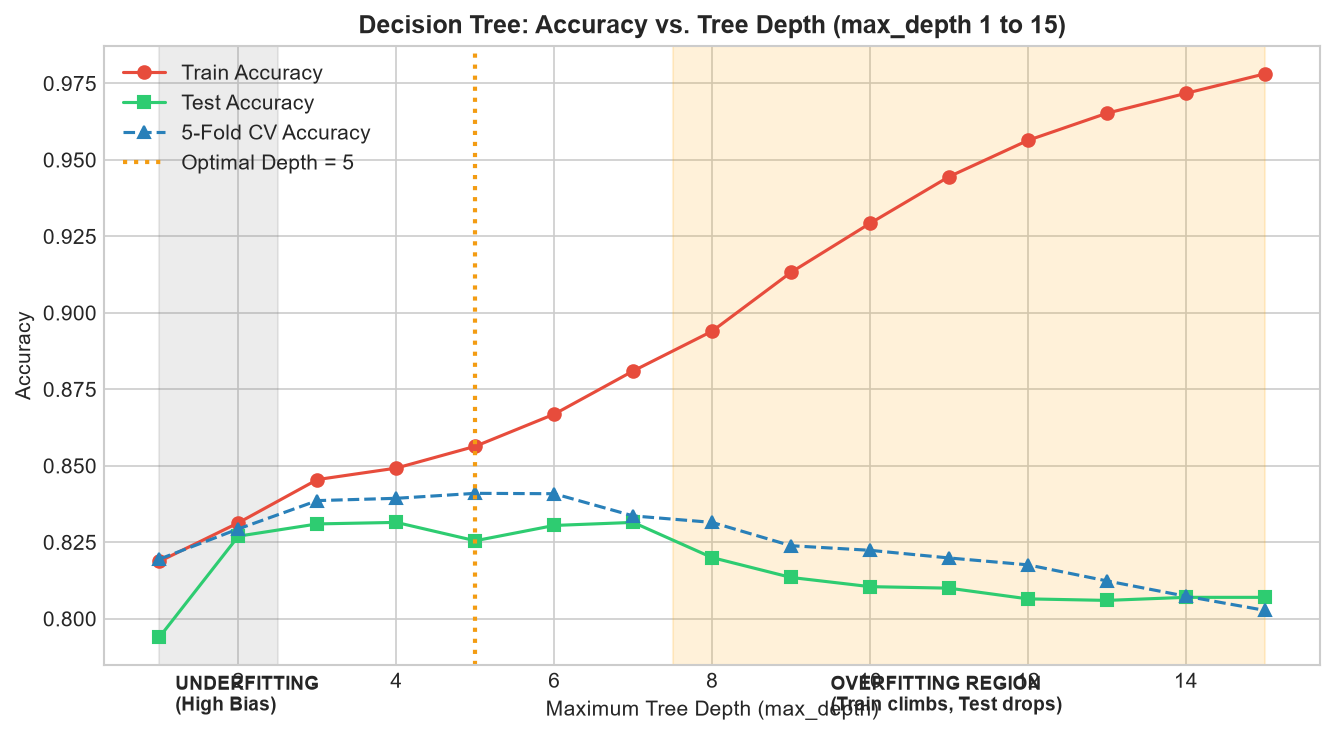

In [6]:
# Visualise Depth Tuning Curve
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(depth_range, train_depth_scores, marker='o', color='#e74c3c', label='Train Accuracy')
ax.plot(depth_range, test_depth_scores, marker='s', color='#2ecc71', label='Test Accuracy')
ax.plot(depth_range, cv_depth_scores, marker='^', color='#2980b9', linestyle='--', label='5-Fold CV Accuracy')
ax.axvline(optimal_depth, color='#f39c12', linestyle=':', lw=2, label=f'Optimal Depth = {optimal_depth}')

# Annotate regions
ax.axvspan(1, 2.5, color='gray', alpha=0.15)
ax.text(1.2, 0.77, 'UNDERFITTING\n(High Bias)', fontsize=9, weight='bold')

ax.axvspan(7.5, 15, color='orange', alpha=0.15)
ax.text(9.5, 0.77, 'OVERFITTING REGION\n(Train climbs, Test drops)', fontsize=9, weight='bold')

ax.set_title('Decision Tree: Accuracy vs. Tree Depth (max_depth 1 to 15)', weight='bold')
ax.set_xlabel('Maximum Tree Depth (max_depth)')
ax.set_ylabel('Accuracy')
ax.legend()

plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_tree_depth_tuning.png', dpi=150)
plt.show()

## 6. Pre-Pruning vs. Post-Pruning (Cost-Complexity Pruning)


In [7]:
# Extract effective alphas from full tree
path = unrestricted_tree.cost_complexity_pruning_path(X_train_trans, y_train)
ccp_alphas = path.ccp_alphas
# Downsample alpha grid for efficient cross-validation
selected_alphas = ccp_alphas[::len(ccp_alphas)//10][:8]
selected_alphas = np.append(selected_alphas, [0.0, 0.001, 0.005])

param_grid_tree = {
    'max_depth': [4, 6, 8, None],
    'min_samples_leaf': [10, 30, 50],
    'ccp_alpha': [0.0, 0.0005, 0.001, 0.005]
}

grid_tree = GridSearchCV(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    param_grid=param_grid_tree,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1
)

grid_tree.fit(X_train_trans, y_train)

best_tree = grid_tree.best_estimator_
y_pred_best_tree = best_tree.predict(X_test_trans)
y_prob_best_tree = best_tree.predict_proba(X_test_trans)[:, 1]

print('=== Best Pruned Tree Hyperparameters ===')
print(f'Best Parameters: {grid_tree.best_params_}')
print(f'Best 5-Fold CV ROC-AUC: {grid_tree.best_score_:.4f}')
print(f'Held-Out Test ROC-AUC:   {roc_auc_score(y_test, y_prob_best_tree):.4f}')
print(f'Held-Out Test Accuracy:  {accuracy_score(y_test, y_pred_best_tree):.4f}')

=== Best Pruned Tree Hyperparameters ===
Best Parameters: {'ccp_alpha': 0.0, 'max_depth': 6, 'min_samples_leaf': 50}
Best 5-Fold CV ROC-AUC: 0.8476
Held-Out Test ROC-AUC:   0.8369
Held-Out Test Accuracy:  0.8270


## 7. Tree Feature Importances vs. Logistic Coefficients


In [8]:
# Extract feature names
feature_names = (
    numeric_cols +
    list(preprocessor.named_transformers_['nom'].named_steps['ohe'].get_feature_names_out(nominal_cols)) +
    ordinal_cols +
    binary_cols
)

tree_importances = best_tree.feature_importances_

df_imp = pd.DataFrame({
    'Feature': feature_names,
    'Gini_Importance': tree_importances
}).sort_values('Gini_Importance', ascending=False).reset_index(drop=True)

df_imp.to_csv('../../outputs/tables/decision_tree_feature_importance.csv', index=False)

print('=== Top 10 Features by Gini Importance ===')
display(df_imp.head(10))

=== Top 10 Features by Gini Importance ===


,Feature,Gini_Importance
0,Credit_Score,0.681486
1,Debt_to_Income,0.126292
2,Late_Payments_2Y,0.050903
3,Employment_Type_Unemployed,0.028791
4,Previous_Default,0.018668
5,Annual_Income,0.014637
6,Credit_Utilization_Pct,0.014375
7,Salary_Account_With_Bank,0.013387
8,Monthly_Debt_Payment,0.011531
9,Loan_to_Income,0.009626


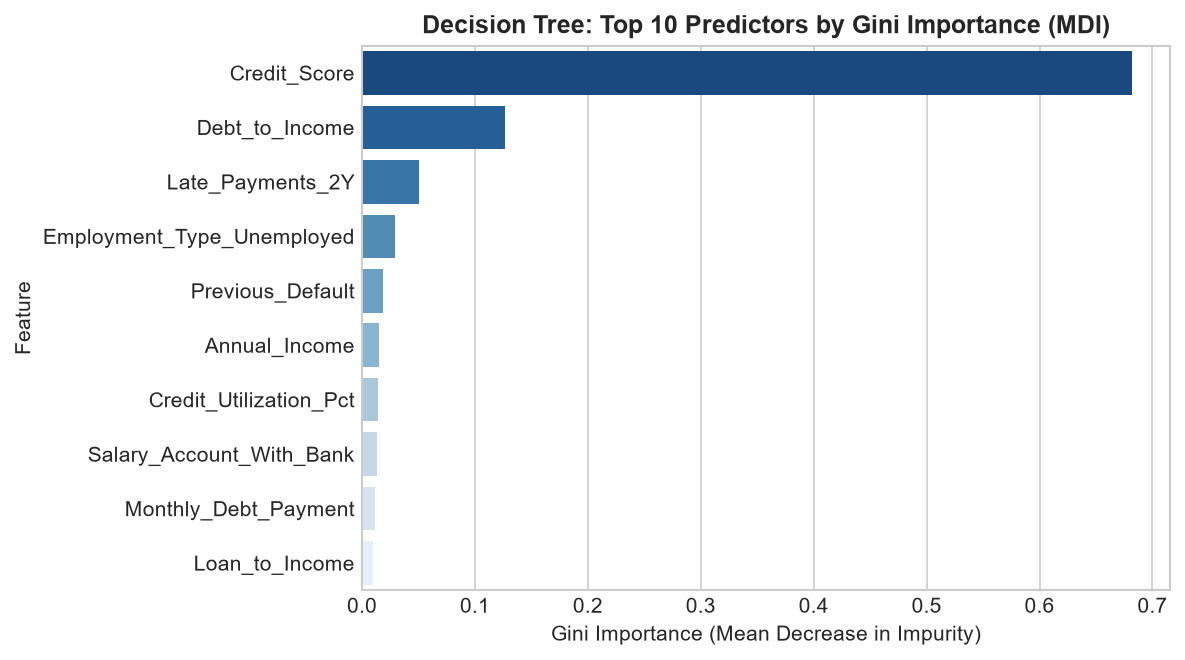

In [9]:
# Visualise Top 10 Features
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=df_imp.head(10), x='Gini_Importance', y='Feature', hue='Feature', palette='Blues_r', ax=ax, legend=False)
ax.set_title('Decision Tree: Top 10 Predictors by Gini Importance (MDI)', weight='bold')
ax.set_xlabel('Gini Importance (Mean Decrease in Impurity)')
plt.tight_layout()
plt.savefig('../../outputs/figures/loan_default_tree_feature_importance.png', dpi=150)
